Loading Fashion-MNIST dataset...
Training images: (60000, 28, 28)
Testing images: (10000, 28, 28)


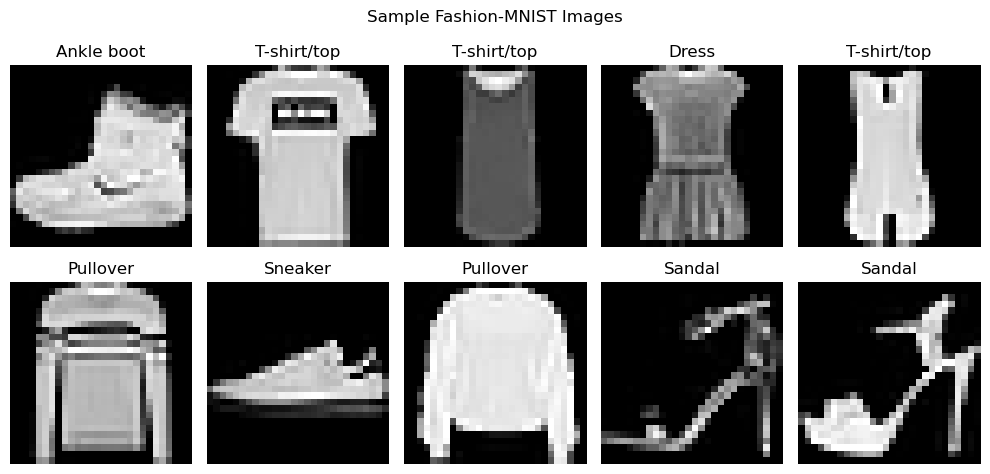

Preprocessed training shape: (60000, 28, 28, 1)
Preprocessed testing shape: (10000, 28, 28, 1)

CNN MODEL SUMMARY


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)                    │ (None, 26, 26, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_4 (MaxPooling2D)       │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_5 (Conv2D)                    │ (None, 11, 11, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_5 (MaxPooling2D)       │ (None, 5, 5, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_2 (Flatten)                  │ (None, 1600)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 64)                  │         102,464 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)


Training CNN model...
Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 108s 123ms/step - accuracy: 0.7892 - loss: 0.5847 - val_accuracy: 0.8513 - val_loss: 0.3951
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 95s 113ms/step - accuracy: 0.8595 - loss: 0.3890 - val_accuracy: 0.8752 - val_loss: 0.3357
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 136s 105ms/step - accuracy: 0.8766 - loss: 0.3403 - val_accuracy: 0.8878 - val_loss: 0.3056
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 143s 106ms/step - accuracy: 0.8873 - loss: 0.3082 - val_accuracy: 0.8908 - val_loss: 0.2967
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 143s 108ms/step - accuracy: 0.8960 - loss: 0.2856 - val_accuracy: 0.8970 - val_loss: 0.2821

MODEL EVALUATION
Test Loss: 0.3071
Test Accuracy: 89.12%


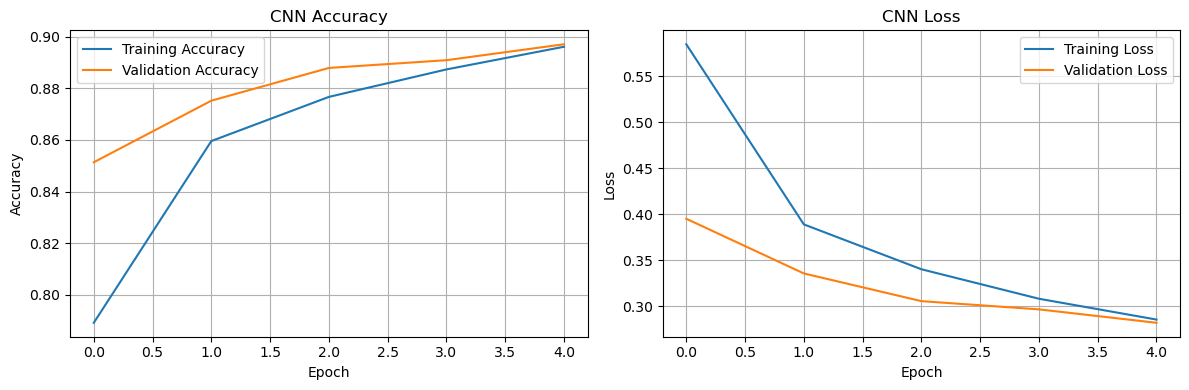

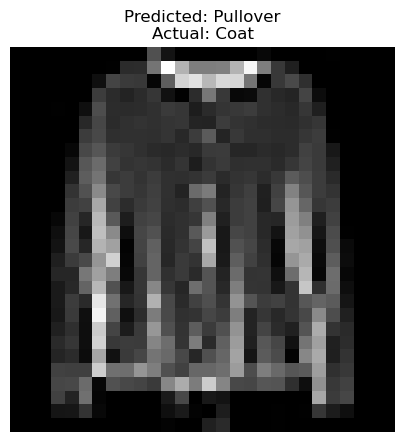


SINGLE IMAGE PREDICTION
Predicted class: Pullover
Actual class: Coat
Prediction confidence: 94.96%


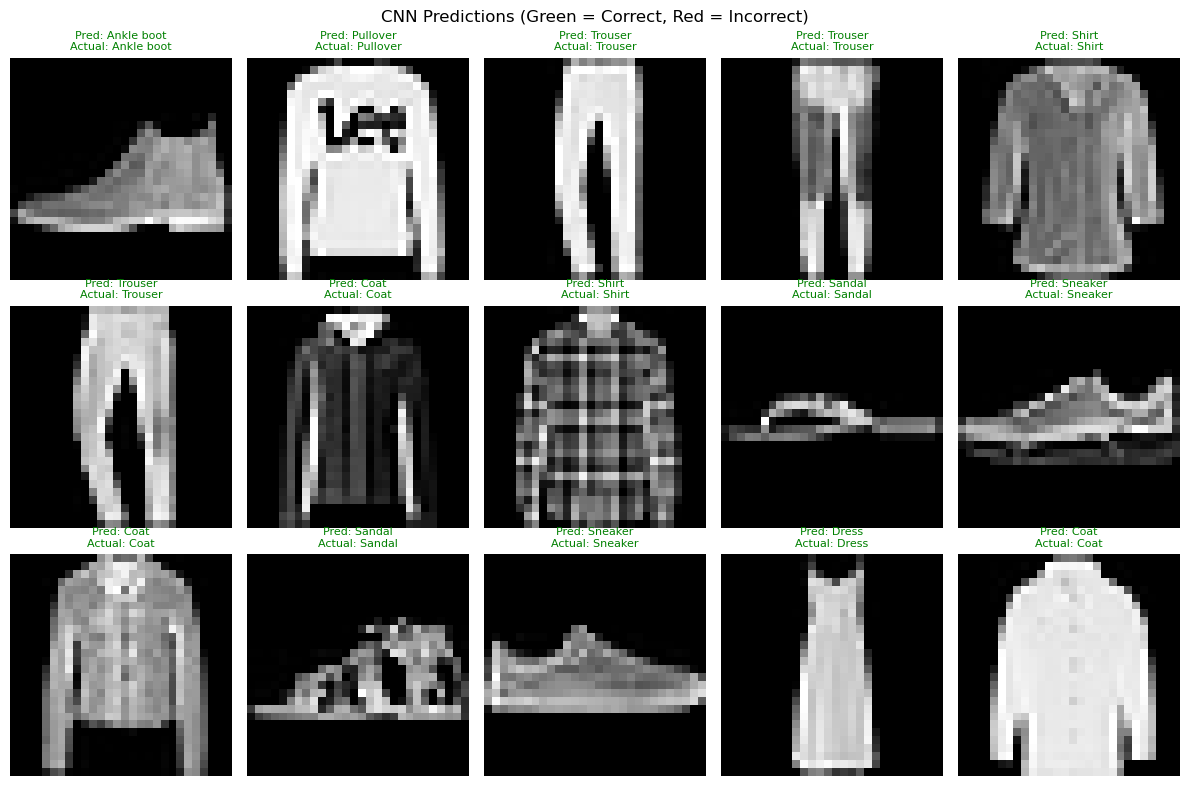


Model saved as fashion_mnist_cnn.keras

PROJECT COMPLETED
Training samples: 60000
Testing samples: 10000
Number of classes: 10
Epochs completed: 5
Final test accuracy: 89.12%
Final test loss: 0.3071
Saved model: fashion_mnist_cnn.keras


In [8]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import os

# 1. SET RANDOM SEED
tf.random.set_seed(42)
np.random.seed(42)

# 2. LOAD FASHION-MNIST DATASET
print("Loading Fashion-MNIST dataset...")

(X_train, y_train), (X_test, y_test) = (
    tf.keras.datasets.fashion_mnist.load_data()
)

class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

print("Training images:", X_train.shape)
print("Testing images:", X_test.shape)

# 3. DISPLAY SAMPLE IMAGES
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(class_names[y_train[i]])
    plt.axis("off")

plt.suptitle("Sample Fashion-MNIST Images")
plt.tight_layout()
plt.show()

# 4. PREPROCESS THE IMAGES
# Normalize pixel values to the range 0–1
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

# Add a channel dimension for grayscale images
X_train = X_train[..., np.newaxis]
X_test = X_test[..., np.newaxis]

print("Preprocessed training shape:", X_train.shape)
print("Preprocessed testing shape:", X_test.shape)

# 5. BUILD THE CNN MODEL
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),

    tf.keras.layers.Conv2D(
        32, kernel_size=(3, 3), activation="relu"
    ),
    tf.keras.layers.MaxPooling2D(pool_size=(2, 2)),

    tf.keras.layers.Conv2D(
        64, kernel_size=(3, 3), activation="relu"
    ),
    tf.keras.layers.MaxPooling2D(pool_size=(2, 2)),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Dense(10, activation="softmax")
])

print("\nCNN MODEL SUMMARY")
model.summary()

# 6. COMPILE THE MODEL
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# 7. TRAIN THE MODEL
print("\nTraining CNN model...")

history = model.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)

# 8. EVALUATE THE MODEL
test_loss, test_accuracy = model.evaluate(
    X_test, y_test, verbose=0
)

print("\nMODEL EVALUATION")
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

# 9. PLOT TRAINING AND VALIDATION ACCURACY/LOSS
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

# 10. PREDICT A SINGLE TEST IMAGE
index = 25

image = X_test[index]
prediction = model.predict(image[np.newaxis, ...], verbose=0)

predicted_class = int(np.argmax(prediction[0]))
actual_class = int(y_test[index])
confidence = float(np.max(prediction[0])) * 100

plt.figure(figsize=(5, 5))
plt.imshow(image.squeeze(), cmap="gray")
plt.title(
    f"Predicted: {class_names[predicted_class]}\n"
    f"Actual: {class_names[actual_class]}"
)
plt.axis("off")
plt.show()

print("\nSINGLE IMAGE PREDICTION")
print("Predicted class:", class_names[predicted_class])
print("Actual class:", class_names[actual_class])
print(f"Prediction confidence: {confidence:.2f}%")

# 11. DISPLAY MULTIPLE PREDICTIONS
plt.figure(figsize=(12, 8))

for i in range(15):
    image = X_test[i]
    prediction = model.predict(
        image[np.newaxis, ...], verbose=0
    )

    predicted_class = int(np.argmax(prediction[0]))
    actual_class = int(y_test[i])

    plt.subplot(3, 5, i + 1)
    plt.imshow(image.squeeze(), cmap="gray")

    color = "green" if predicted_class == actual_class else "red"

    plt.title(
        f"Pred: {class_names[predicted_class]}\n"
        f"Actual: {class_names[actual_class]}",
        color=color,
        fontsize=8
    )
    plt.axis("off")

plt.suptitle("CNN Predictions (Green = Correct, Red = Incorrect)")
plt.tight_layout()
plt.show()

# 12. SAVE THE TRAINED MODEL
model.save("fashion_mnist_cnn.keras")
print("\nModel saved as fashion_mnist_cnn.keras")

# 13. DISPLAY FINAL RESULTS
print("\n" + "=" * 40)
print("PROJECT COMPLETED")
print("=" * 40)
print(f"Training samples: {len(X_train)}")
print(f"Testing samples: {len(X_test)}")
print(f"Number of classes: {len(class_names)}")
print(f"Epochs completed: {len(history.history['loss'])}")
print(f"Final test accuracy: {test_accuracy * 100:.2f}%")
print(f"Final test loss: {test_loss:.4f}")
print("Saved model: fashion_mnist_cnn.keras")